## Open-loop vs. Assimilated NLL & Attenuation Bias Illustrations

We use the 1-d chaotic tent map and logistic map to illustrate open-loop vs. filtered innovation NLL and the log-volume pressure in the open-loop Gaussian NLL as well as the attenuation bias through errors-in-variables regression in dynamical systems.

The tent-map panels are written as one figure, `figures/tent_logistic_nll/tent_likelihood`. The logistic map figure is written to `figures/tent_logistic_nll/logistic_attenuation_bifurcation`.


In [1]:
from pathlib import Path
import importlib.util
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
from numpy.polynomial.hermite import hermgauss
from scipy.stats import gaussian_kde


def set_thread_env(n_threads=4):
    for var in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
        os.environ[var] = str(n_threads)
    torch.set_num_threads(n_threads)


set_thread_env(4)

COLOR_ORANGE = "#e07b39"  # chaos-onset
COLOR_CURVE = "#2c6aa0"  # r*(sigma) curve

%matplotlib inline

NOTEBOOK_DIR = Path.cwd().resolve()
REPO_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
OUTPUT_DIR = REPO_ROOT / "figures" / "tent_logistic_nll"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

_spec = importlib.util.spec_from_file_location(
    "paper_figure_style", REPO_ROOT / "figures" / "paper_style.py"
)
_paper_style = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(_paper_style)

_P55 = _paper_style.points(5.19)
_RC55 = _paper_style.rc_params(5.19)


def despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def save_figure(fig, stem):
    fig.savefig(OUTPUT_DIR / f"{stem}.png", dpi=200, bbox_inches="tight", pad_inches=0.01)
    fig.savefig(OUTPUT_DIR / f"{stem}.pdf", dpi=200, bbox_inches="tight", pad_inches=0.01)


In [2]:
tent_s = 1.8 # tent map parameter
tent_obs_std = 0.02 # observation noise
tent_std_zt = 0.04 # transition noise
tent_mu0 = 0.5 # initial mean
tent_std_z0 = 0.01 # initial noise
tent_R = tent_obs_std**2 # observation variance
tent_Q = tent_std_zt**2 # transition variance
tent_P0 = tent_std_z0**2 # initial covariance

T_TENT = 5 # number of time steps to plot


def _as_torch(*values):
    return [torch.as_tensor(v, dtype=torch.float64) for v in values]


def log_normal(x, mean, var):
    """Log-normal density"""
    if isinstance(x, torch.Tensor) or isinstance(mean, torch.Tensor) or isinstance(var, torch.Tensor):
        x, mean, var = (torch.as_tensor(v, dtype=torch.float64) for v in (x, mean, var))
        return -0.5 * (torch.log(2 * torch.pi * var) + (x - mean) ** 2 / var)
    return -0.5 * (np.log(2 * np.pi * var) + (x - mean) ** 2 / var)


def gaussian_pdf(x, mean, var):
    """Gaussian density"""
    return np.exp(log_normal(np.asarray(x), mean, var))


def tent_mean(z, slope):
    """Tent map mean function"""
    if isinstance(z, torch.Tensor) or isinstance(slope, torch.Tensor):
        z = torch.as_tensor(z, dtype=torch.float64)
        return torch.where(z < 0.5, slope * z, slope * (1.0 - z))
    z = np.asarray(z, dtype=np.float64)
    return np.where(z < 0.5, slope * z, slope * (1.0 - z))


def tent_transition(z, rng, slope=tent_s):
    """Tent map transition function (mean + noise)"""
    noisy = tent_mean(z, slope) + tent_std_zt * rng.normal(size=np.shape(z))
    return np.clip(noisy, 0.0, 1.0) # ensure boundedness


def tent_update(m, P, x, obs_var=tent_R):
    """EKF update step"""
    S = P + obs_var
    K = P / S
    return m + K * (x - m), (1.0 - K) * P


def tent_ekf_predict(m, P, slope=tent_s, transition_var=tent_Q):
    """EKF prediction step"""
    return tent_mean(m, slope), slope**2 * P + transition_var


def sample_tent_trajectory(rng, max_h, slope=tent_s):
    """Sample a tent map trajectory"""
    z = tent_mu0 + tent_std_z0 * rng.normal()
    xs = []
    for t in range(max_h + 1):
        xs.append(z + tent_obs_std * rng.normal())
        if t < max_h:
            z = tent_transition(z, rng, slope)
    return np.asarray(xs, dtype=np.float64)


def tent_mc_open_loop(rng, n_samples, h, x0):
    """Open-loop Monte Carlo sampling"""
    m, P = tent_update(tent_mu0, tent_P0, x0)
    z = m + np.sqrt(P) * rng.normal(size=n_samples)
    for _ in range(h):
        z = tent_transition(z, rng)
    return z + tent_obs_std * rng.normal(size=z.shape)


def tent_mc_assimilated_pf(rng, n_samples, h, xs_obs, n_particles=40_000):
    """Assimilated particle filter sampling, using the bootstrap proposal"""
    particles = tent_mu0 + tent_std_z0 * rng.normal(size=n_particles)
    for t in range(h):
        log_w = log_normal(xs_obs[t], particles, tent_R) # for bootstrap proposal is just observation likelihood
        log_w = log_w - np.max(log_w)
        weights = np.exp(log_w)
        weights = weights / weights.sum() # normalize to get weights
        indices = rng.choice(n_particles, size=n_particles, replace=True, p=weights) # sample particles with replacement
        particles = tent_transition(particles[indices], rng) # propagate particles
    selected = particles[rng.integers(0, n_particles, size=n_samples)]
    return selected + tent_obs_std * rng.normal(size=selected.shape) # add observation noise


def tent_ekf_open_stats(h, x0):
    """Open-loop EKF (with prediction step)"""
    m, P = tent_update(tent_mu0, tent_P0, x0)
    for _ in range(h):
        m, P = tent_ekf_predict(m, P)
    return float(m), float(P + tent_R)


def tent_ekf_assimilated_stats(xs_prefix):
    """Assimilated EKF (with update step)"""
    m, P = tent_mu0, tent_P0
    for x in xs_prefix:
        m, P = tent_update(m, P, x)
        m, P = tent_ekf_predict(m, P)
    return float(m), float(P + tent_R)


rng = np.random.default_rng(20)
tent_xs = sample_tent_trajectory(rng, T_TENT)
tent_x0 = tent_xs[0]
print("tent-map observation trajectory:", tent_xs)


tent-map observation trajectory: [0.52047682 0.95574541 0.09785312 0.13918738 0.26159711 0.43773732]


In [3]:
# Parameter learning
# ------------------

TENT_N_DATA = 50_000 # number of trajectories
TENT_N_STEPS = 1_000 # number of training steps
TENT_LR = 1e-2
T_TENT = 25 # number of time steps


def tent_unpack(raw):
    """constrained parameters"""
    obs = torch.exp(raw[0])
    transition = torch.exp(raw[1])
    slope = 2.0 * torch.sigmoid(raw[2])
    return obs, transition, slope


def tent_init_raw(obs, transition, slope):
    slope_unit = float(np.clip(slope / 2.0, 1e-4, 1 - 1e-4))
    return torch.tensor([
        np.log(obs),
        np.log(transition),
        np.log(slope_unit / (1.0 - slope_unit)),
    ], dtype=torch.float64)


def sample_tent_batch(rng):
    z = tent_mu0 + tent_std_z0 * rng.normal(size=TENT_N_DATA)
    x0 = z + tent_obs_std * rng.normal(size=z.shape)
    xs = [x0]
    for _ in range(T_TENT):
        z = tent_transition(z, rng)
        xs.append(z + tent_obs_std * rng.normal(size=z.shape))
    return np.stack(xs, axis=1)


def tent_open_nll(raw, xs):
    obs, transition, slope = tent_unpack(raw)
    R, Q = obs**2, transition**2
    m, P = tent_update(torch.tensor(tent_mu0, dtype=torch.float64), torch.tensor(tent_P0, dtype=torch.float64), xs[:, 0], R)
    total = xs.new_zeros(())
    for t in range(1, xs.shape[1]):
        m, P = tent_ekf_predict(m, P, slope=slope, transition_var=Q)
        total = total + log_normal(xs[:, t], m, P + R).mean()
    return -total / (xs.shape[1] - 1)


def tent_assimilated_nll(raw, xs):
    obs, transition, slope = tent_unpack(raw)
    R, Q = obs**2, transition**2
    m = torch.full((xs.shape[0],), tent_mu0, dtype=torch.float64)
    P = torch.tensor(tent_P0, dtype=torch.float64)
    total = xs.new_zeros(())
    for t in range(xs.shape[1] - 1):
        m, P = tent_update(m, P, xs[:, t], R)
        m, P = tent_ekf_predict(m, P, slope=slope, transition_var=Q)
        total = total + log_normal(xs[:, t + 1], m, P + R).mean()
    return -total / (xs.shape[1] - 1)


def fit_tent(loss_fn, raw0, xs):
    raw = raw0.detach().clone().requires_grad_(True)
    optimizer = torch.optim.Adam([raw], lr=TENT_LR)
    for _ in range(TENT_N_STEPS):
        optimizer.zero_grad()
        loss = loss_fn(raw, xs)
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        final = float(loss_fn(raw, xs))
    return raw.detach(), final


rng_fit = np.random.default_rng(21)
tent_fit_data = torch.as_tensor(sample_tent_batch(rng_fit), dtype=torch.float64)
tent_raw0 = tent_init_raw(tent_obs_std * 2.0, tent_std_zt * 2.0, tent_s * 0.75)
tent_fits = {
    "open loop": fit_tent(tent_open_nll, tent_raw0, tent_fit_data),
    "assimilated": fit_tent(tent_assimilated_nll, tent_raw0, tent_fit_data),
}

for name, (raw, loss) in tent_fits.items():
    obs_hat, transition_hat, slope_hat = tent_unpack(raw)
    print(f"\n{name} (mean NLL={loss:.4f})")
    print(f"  obs_std: learned {float(obs_hat):.5f}, true {tent_obs_std:.5f}")
    print(f"  std_zt : learned {float(transition_hat):.5f}, true {tent_std_zt:.5f}")
    print(f"  slope  : learned {float(slope_hat):.5f}, true {tent_s:.5f}")
    print(f"  lambda : learned {float(torch.log(slope_hat)):.5f}, true {float(np.log(tent_s)):.5f}")


def tent_fixed_noise_profile(slopes, xs):
    """Open-loop and filtered NLL, plus the open-loop log-volume and Mahalanobis terms, at fixed noise."""
    slopes = torch.as_tensor(slopes, dtype=torch.float64)
    n_slopes = slopes.shape[0]
    x0 = xs[:, 0]
    m0, p0 = tent_update(
        torch.tensor(tent_mu0, dtype=torch.float64),
        torch.tensor(tent_P0, dtype=torch.float64),
        x0,
        tent_R,
    )
    # Open loop
    m = m0[None, :].expand(n_slopes, -1).clone()
    P = p0.reshape(1, 1).expand(n_slopes, 1).clone()
    logvol = torch.zeros(n_slopes, dtype=torch.float64)
    mahal = torch.zeros(n_slopes, dtype=torch.float64)
    nll_open = torch.zeros(n_slopes, dtype=torch.float64)
    for t in range(1, xs.shape[1]):
        m, P = tent_ekf_predict(m, P, slope=slopes[:, None], transition_var=tent_Q)
        omega = P + tent_R
        resid = xs[:, t] - m
        logvol = logvol + 0.5 * torch.log(omega).mean(dim=1)
        mahal = mahal + (0.5 * resid**2 / omega).mean(dim=1)
        nll_open = nll_open - log_normal(xs[:, t], m, omega).mean(dim=1)
    n_steps = xs.shape[1] - 1
    # Filtered
    m = torch.full((n_slopes, xs.shape[0]), tent_mu0, dtype=torch.float64)
    P = torch.full((n_slopes, 1), tent_P0, dtype=torch.float64)
    nll_filtered = torch.zeros(n_slopes, dtype=torch.float64)
    for t in range(n_steps):
        m, P = tent_update(m, P, xs[:, t], tent_R)
        m, P = tent_ekf_predict(m, P, slope=slopes[:, None], transition_var=tent_Q)
        nll_filtered = nll_filtered - log_normal(xs[:, t + 1], m, P + tent_R).mean(dim=1)
    return (
        (nll_open / n_steps).numpy(),
        (nll_filtered / n_steps).numpy(),
        (logvol / n_steps).numpy(),
        (mahal / n_steps).numpy(),
    )


tent_s_grid = np.linspace(0.6, 1.99, 100)
(
    tent_ol_profile,
    tent_as_profile,
    tent_logvol_profile,
    tent_mahal_profile,
) = tent_fixed_noise_profile(tent_s_grid, tent_fit_data)

tent_ol_profile_opt = float(tent_s_grid[np.argmin(tent_ol_profile)])
tent_as_profile_opt = float(tent_s_grid[np.argmin(tent_as_profile)])
print(
    f"\nfixed-noise profile: true slope={tent_s:.3f}, "
    f"OL optimum={tent_ol_profile_opt:.3f}, "
    f"AS optimum={tent_as_profile_opt:.3f}"
)



open loop (mean NLL=-0.0320)
  obs_std: learned 0.22725, true 0.02000
  std_zt : learned 0.00809, true 0.04000
  slope  : learned 1.06544, true 1.80000
  lambda : learned 0.06339, true 0.58779

assimilated (mean NLL=-1.4787)
  obs_std: learned 0.02018, true 0.02000
  std_zt : learned 0.03924, true 0.04000
  slope  : learned 1.79393, true 1.80000
  lambda : learned 0.58441, true 0.58779

fixed-noise profile: true slope=1.800, OL optimum=1.091, AS optimum=1.793


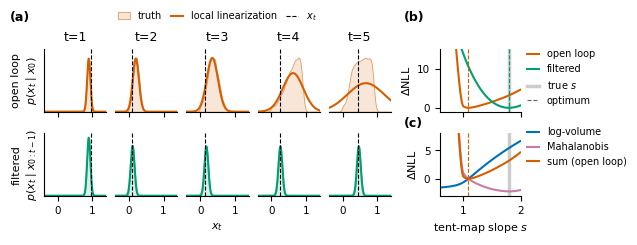

In [ ]:
import matplotlib

n_hist = 5
lo, hi = -0.4, 1.4
xs = np.linspace(lo, hi, 300)
rng_fig = np.random.default_rng(20)

FIG2_SIZE = (6.15, 1.9)
_fig2_pt = _paper_style.points(_paper_style.REFERENCE_WIDTH_IN)
_fig2_rc = _paper_style.rc_params(_paper_style.REFERENCE_WIDTH_IN)
_fig2_rc.update({"mathtext.fontset": "dejavusans", "mathtext.default": "it"})
with plt.rc_context(_fig2_rc):
    fig = plt.figure(figsize=FIG2_SIZE)
    gs = fig.add_gridspec(2, n_hist + 2, width_ratios=[1] * n_hist + [0.5, 1.3], hspace=0.35, wspace=0.15)
    hist_axes = [[fig.add_subplot(gs[row, h]) for h in range(n_hist)] for row in range(2)]
    ax_nll = fig.add_subplot(gs[0, n_hist + 1])
    ax_dec = fig.add_subplot(gs[1, n_hist + 1], sharex=ax_nll)

    for h in range(1, n_hist + 1):
        ol_mc = tent_mc_open_loop(rng_fig, 20_000, h, tent_x0)
        as_mc = tent_mc_assimilated_pf(rng_fig, 20_000, h, tent_xs)
        for row, samples, (mean, var), color in [
            (0, ol_mc, tent_ekf_open_stats(h, tent_x0), "#D55E00"),
            (1, as_mc, tent_ekf_assimilated_stats(tent_xs[:h]), "#009E73"),
        ]:
            ax = hist_axes[row][h - 1]
            true_pdf = gaussian_kde(np.asarray(samples))(xs)
            ax.fill_between(xs, true_pdf, facecolor=matplotlib.colors.to_rgba(color, 0.15), edgecolor=matplotlib.colors.to_rgba(color, 0.6), lw=0.6, label="truth")
            ax.plot(xs, gaussian_pdf(xs, mean, var), color=color, label="local linearization")
            ax.axvline(tent_xs[h], color="k", ls="--", lw=0.8, label="$x_t$")
            ax.set_xlim(lo, hi)
            ax.set_ylim(0, 1.15 * max(float(true_pdf.max()), float(gaussian_pdf(mean, mean, var))) if row == 0 else 9)
            ax.set_xticks([0, 1])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(f"t={h}")
                ax.set_xticklabels([])
            if h > 1:
                ax.spines["left"].set_visible(False)

    hist_axes[0][0].set_ylabel("open loop\n$p(x_t\\mid x_0)$")
    hist_axes[1][0].set_ylabel("filtered\n$p(x_t\\mid x_{0:t-1})$")

    ax_nll.plot(tent_s_grid, tent_ol_profile - tent_ol_profile.min(), color="#D55E00", label="open loop")
    ax_nll.plot(tent_s_grid, tent_as_profile - tent_as_profile.min(), color="#009E73", label="filtered")
    ax_nll.set_xlim(0.6, 2)
    ax_nll.axvline(tent_s, color="0.8", lw=2.5, zorder=0, label="true $s$")
    ax_nll.axvline(tent_ol_profile_opt, color="#D55E00", ls="--", lw=0.8)
    ax_nll.axvline(tent_as_profile_opt, color="#009E73", ls="--", lw=0.8)
    ax_nll.plot([], [], color="0.4", ls="--", lw=0.8, label="optimum")
    ax_nll.set_ylabel(r"$\Delta$NLL")
    ax_nll.set_ylim(-1, 15)
    ax_nll.tick_params(labelbottom=False)
    ax_nll.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1.1), fontsize=_fig2_pt["legend"], handlelength=1.25, borderpad=0.12)

    # open-loop NLL = log-volume + Mahalanobis (+ const); both shifted to zero at the open-loop optimum
    i_ol = int(np.argmin(tent_ol_profile))
    ax_dec.plot(tent_s_grid, tent_logvol_profile - tent_logvol_profile[i_ol], color="#0072B2", label="log-volume")
    ax_dec.plot(tent_s_grid, tent_mahal_profile - tent_mahal_profile[i_ol], color="#CC79A7", label="Mahalanobis")
    ax_dec.plot(tent_s_grid, tent_ol_profile - tent_ol_profile[i_ol], color="#D55E00", label="sum (open loop)")
    ax_dec.axvline(tent_s, color="0.8", lw=2.5, zorder=0)
    ax_dec.axvline(tent_ol_profile_opt, color="#D55E00", ls="--", lw=0.8)
    ax_dec.set_xlabel("tent-map slope $s$")
    ax_dec.set_ylabel(r"$\Delta$NLL")
    ax_dec.set_ylim(-3, 8)
    ax_dec.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1.2), fontsize=_fig2_pt["legend"], handlelength=1.25, borderpad=0.12)

    fig.canvas.draw()
    pos_l = hist_axes[0][0].get_position()
    pos_r = hist_axes[0][-1].get_position()
    x_center = 0.5 * (pos_l.x0 + pos_r.x1)
    renderer = fig.canvas.get_renderer()
    tick_bottom = min(
        fig.transFigure.inverted().transform((0.0, lab.get_window_extent(renderer=renderer).y0))[1]
        for ax in hist_axes[1]
        for lab in ax.get_xticklabels()
        if lab.get_text()
    )
    fig.text(
        x_center,
        tick_bottom - 4.0 / (FIG2_SIZE[1] * 72.0),
        r"$x_t$",
        ha="center",
        va="top",
        fontsize=_fig2_pt["label"],
    )
    title_top = max(
        fig.transFigure.inverted().transform(ax.title.get_window_extent(renderer=renderer).max)[1]
        for ax in hist_axes[0]
    )
    handles, labels = hist_axes[0][0].get_legend_handles_labels()
    hist_legend = fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(x_center, title_top + 0.012),
        bbox_transform=fig.transFigure,
        ncol=3,
        frameon=False,
        fontsize=_fig2_pt["legend"],
        handlelength=1.25,
        borderpad=0.12,
        columnspacing=0.9,
    )
    fig.canvas.draw()
    legend_box = hist_legend.get_window_extent(renderer=fig.canvas.get_renderer())
    legend_mid_y = 0.5 * (legend_box.y0 + legend_box.y1)
    for ax, x_letter, letter in (
        (hist_axes[0][0], -0.55, "(a)"),
        (ax_nll, -0.45, "(b)"),
    ):
        _, y_axes = ax.transAxes.inverted().transform((0, legend_mid_y))
        ax.text(x_letter, y_axes, letter, transform=ax.transAxes, ha="left", va="center", fontsize=_fig2_pt["panel"], fontweight="bold", clip_on=False)
    ax_dec.text(-0.45, 1.1, "(c)", transform=ax_dec.transAxes, fontsize=_fig2_pt["panel"], fontweight="bold")
    save_figure(fig, "tent_likelihood")
    plt.show()


r*(0)=4.000000
sigma(r_inf)=0.0829
sigma(r=3)=0.1294


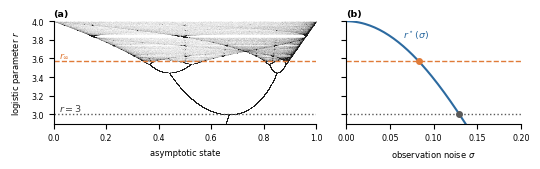

In [12]:
R_TRUE = 4.0  # true logistic parameter (fully chaotic)
R_INF = 3.57  # Onset of chaos
R_PERIOD2 = 3.0  # period-2 bifurcation onset

SEED = 0  
N_BIFURCATION_R = 2200  # r-grid size for bifurcation diagram
N_BIFURCATION_TRANSIENT = 1200  # burn-in before plotting
N_BIFURCATION_PLOT = 220  # plotted iterates per r
SIGMA_GRID = np.linspace(0.0, 0.45, 250)  # observation-noise grid for r*(sigma) curve
N_QUAD_U = 8000  # quadrature points
N_QUAD_GH = 32  # Gauss-Hermite nodes
R_MIN = 2.9  # lower r-axis limit of the bifurcation diagram


def logistic_map(x, r):
    return r * x * (1.0 - x)

def population_r_star(sigmas, n_u=N_QUAD_U, n_gh=N_QUAD_GH):
    """Population least-squares slope of the r=4 logistic map fit to noisy states.

    z follows the invariant density sin^2(pi U), U uniform on (0, 1). With
    y = z + sigma * eps and eps standard normal,
    r*(sigma) = E[z_next * y(1-y)] / E[y(1-y)^2].
    """
    u = (np.arange(n_u) + 0.5) / n_u 
    z = np.sin(np.pi * u) ** 2  
    z_next = logistic_map(z, R_TRUE)
    nodes, weights = hermgauss(n_gh)
    eps = np.sqrt(2.0) * nodes
    w = weights / np.sqrt(np.pi)
    out = np.empty(np.shape(sigmas), dtype=np.float64)
    for i, sigma in enumerate(np.atleast_1d(sigmas)):
        y = z[:, None] + float(sigma) * eps[None, :] 
        g = y * (1.0 - y)  
        num = np.mean((z_next[:, None] * g) @ w)  
        den = np.mean((g * g) @ w)  
        out[i] = num / den 
    return out


def interpolate_sigma(sigma, r_star, target):
    return float(np.interp(target, r_star[::-1], sigma[::-1]))


def bifurcation_cloud(r_grid, *, n_transient, n_plot, seed):
    rng = np.random.default_rng(seed)
    x = 0.05 + 0.9 * rng.random(r_grid.shape[0])
    for _ in range(n_transient):
        x = logistic_map(x, r_grid)
    rs = np.empty((n_plot, r_grid.shape[0]), dtype=np.float64)
    xs = np.empty_like(rs)
    for i in range(n_plot):
        x = logistic_map(x, r_grid)
        rs[i] = r_grid
        xs[i] = x
    return rs.ravel(), xs.ravel()


r_star = population_r_star(SIGMA_GRID)
sigma_inf = interpolate_sigma(SIGMA_GRID, r_star, R_INF)  # noise level where r*(sigma) = r_inf
sigma_period2 = interpolate_sigma(SIGMA_GRID, r_star, R_PERIOD2)  # noise level where r*(sigma) = 3
r_b, x_b = bifurcation_cloud(
    np.linspace(R_MIN, 4.0, N_BIFURCATION_R),
    n_transient=N_BIFURCATION_TRANSIENT,
    n_plot=N_BIFURCATION_PLOT,
    seed=SEED + 1,
) 
print(f"r*(0)={r_star[0]:.6f}")
print(f"sigma(r_inf)={sigma_inf:.4f}")
print(f"sigma(r=3)={sigma_period2:.4f}")

with plt.rc_context(_RC55):
    fig, axes = plt.subplots(
        1, 2, figsize=(5.5, 1.81), sharey=True, gridspec_kw={"width_ratios": [3, 2]}
    )
    axes[0].scatter(
        x_b, r_b, s=0.015, c="0.12", alpha=0.2, linewidths=0, rasterized=True
    )
    axes[0].axhline(R_INF, color=COLOR_ORANGE, ls="--", lw=1.0)
    axes[0].axhline(R_PERIOD2, color="0.35", ls=":", lw=1.0)
    axes[0].text(0.02, R_INF + 0.04, r"$r_\infty$", color=COLOR_ORANGE, fontsize=_P55["panel"])
    axes[0].text(0.02, R_PERIOD2 + 0.04, r"$r=3$", color="0.25", fontsize=_P55["panel"])
    axes[0].text(0.0, 1.03, "(a)", transform=axes[0].transAxes, ha="left", va="bottom", fontsize=_P55["panel"], fontweight="bold", clip_on=False)
    axes[0].set_xlabel("asymptotic state")
    axes[0].set_ylabel("logistic parameter $r$", labelpad=6)
    axes[0].yaxis.label.set_fontsize(_P55["label"])
    axes[0].yaxis.label.set_clip_on(False)
    axes[0].set_xlim(0.0, 1.0)
    axes[0].set_ylim(R_MIN, 4.0)

    axes[1].plot(SIGMA_GRID, r_star, color=COLOR_CURVE, lw=1.5)
    axes[1].axhline(R_INF, color=COLOR_ORANGE, ls="--", lw=1.0)
    axes[1].axhline(R_PERIOD2, color="0.35", ls=":", lw=1.0)
    axes[1].scatter([sigma_inf], [R_INF], s=16, color=COLOR_ORANGE, zorder=5)
    axes[1].scatter([sigma_period2], [R_PERIOD2], s=16, color="0.35", zorder=5)
    sigma_label = interpolate_sigma(SIGMA_GRID, r_star, 3.65)  # some anchor to place the r*(sigma) label
    axes[1].text(
        sigma_label - 0.01,
        3.85,
        r"$r^\star(\sigma)$",
        color=COLOR_CURVE,
        fontsize=_P55["title"],
        ha="left",
        va="center",
    )
    axes[1].text(0.0, 1.03, "(b)", transform=axes[1].transAxes, ha="left", va="bottom", fontsize=_P55["panel"], fontweight="bold", clip_on=False)
    axes[1].set_xlabel(r"observation noise $\sigma$")
    axes[1].set_xlim(0.0, 0.2)
    axes[1].set_ylim(R_MIN, 4.0)

    for ax in axes.flat:
        despine(ax)
    plt.tight_layout()
    save_figure(fig, "logistic_attenuation_bifurcation")
    plt.show()
